# 04 · Conversion: apply `normalize` and `convert`, then measure

**Input:** `data/processed/master_clean.csv` · **Output:** `data/processed/master_converted.csv.gz`

Part A adds two columns and changes nothing else:
- `text_norm` = `normalize(text)` (used in both conditions)
- `text_conv` = `convert(text)` (normalize + shared vowel-free form)

Part B measures overlap before vs after and the character error rate (CER) on the manual sample.

In [1]:
# 1. Setup: find the repo root (works locally and in Colab)
import sys, os
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # the repository is cloned into /content first
    os.chdir("/content/tunisian-sentiment")
    ROOT = Path.cwd()
else:
    ROOT = Path.cwd()
    while not (ROOT / "src" / "transliteration.py").exists():
        if ROOT == ROOT.parent:
            raise FileNotFoundError("Could not find src/transliteration.py: open the notebook inside the repo")
        ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
print("Repo root found:", ROOT.name)

Repo root found: tunisian-sentiment


In [2]:
# 2. Imports and reload the module (so edits to transliteration.py are picked up)
import importlib
import pandas as pd
import transliteration
importlib.reload(transliteration)
from transliteration import normalize, convert, VERSION, CHANGELOG

print("transliteration version:", VERSION)
for line in CHANGELOG:
    print(" -", line)

transliteration version: 1
 - v1: initial version.


In [3]:
# 3. Read master_clean.csv
IN_PATH = ROOT / "data" / "processed" / "master_clean.csv"
OUT_PATH = ROOT / "data" / "processed" / "master_converted.csv.gz"

df = pd.read_csv(IN_PATH, encoding="utf-8")
print(df.shape)
print(df.columns.tolist())
assert {"id", "text", "label", "source", "split", "script"} <= set(df.columns), "missing master columns"
assert df["text"].notna().all(), "text has missing values: fix in the cleaning step, not here"
df.head()

(111531, 11)
['id', 'text', 'label', 'source', 'split', 'script', 'n_chars', 'n_words', 'has_emoji', 'has_arabizi_digits', 'has_elongation']


,id,text,label,source,split,script,n_chars,n_words,has_emoji,has_arabizi_digits,has_elongation
0,tunizi_000001,7yeti ca ya slouma,pos,tunizi,train,arabizi,18,4,False,True,False
1,tunizi_000002,rabi yehdik aka chenajmou n9oulo,pos,tunizi,train,arabizi,32,5,False,True,False
2,tunizi_000003,amazing like usual,pos,tunizi,train,arabizi,18,3,False,False,False
3,tunizi_000004,bonne chance docteur marzouki vive cpr,pos,tunizi,train,arabizi,38,6,False,False,False
4,tunizi_000005,allah yarhmou we rabi saber ahlo,pos,tunizi,train,arabizi,32,6,False,False,False


In [4]:
# 4. Apply
# False = all vowels removed (a e i o u w y). Part B compares this with the variant
# that keeps w and y: removing them gives the lower CER (0.105 vs 0.196).
KEEP_WY = False

df["text_norm"] = df["text"].map(normalize)
df["text_conv"] = df["text"].map(lambda t: convert(t, keep_wy=KEEP_WY))
df[["script", "text", "text_norm", "text_conv"]].sample(8, random_state=42)

,script,text,text_norm,text_conv
49122,arabizi,kol 3amou tounis elkol bkhir,kol 3amou tounis elkol bkhir,kl 3m tns lkl b5r
10243,arabizi,il 7oooooooooooot 3lik ya kayedhom,il 7ot 3lik ya kayedhom,l 7t 3lk kdhm
47973,arabizi,bravo pour ce film,bravo pour ce film,brv pr c flm
108533,arabizi,enta m3alem (y),enta m3alem (y),nt m3lm ()
40758,arabizi,club hhh club hhh yaki mezelit haya hata bil m...,club h club h yaki mezelit haya hata bil milya...,clb h clb h k mzlt h ht bl mlrt ch n f bl 40 mlr
90984,arabizi,sorry mr president ama fama milaf esmou milaf ...,sorry mr president ama fama milaf esmou milaf ...,sr mr prsdnt m fm mlf sm mlf ljr7 l m7sb lfsd ...
61729,arabizi,mala video 5ihhhhhh 3andou el 7a9 slm mr,mala video 5ih 3andou el 7a9 slm mr,ml vd 5h 3nd l 79 slm mr
17250,arabizi,allah yarehemou et naamou bel janna inchallah,allah yarehemou et naamou bel janna inchallah,lh rhm t nm bl jn nchlh


In [5]:
# 5. Sanity checks before saving
assert len(df) == pd.read_csv(IN_PATH, usecols=["id"]).shape[0], "row count changed"
assert df["id"].is_unique

# Rows whose converted text became empty (e.g. a comment made only of vowels)
empty_conv = df["text_conv"].str.len() == 0
print("Empty text_norm:", int((df["text_norm"].str.len() == 0).sum()))
print("Empty text_conv:", int(empty_conv.sum()), f"({empty_conv.mean():.2%})")
print(df.loc[empty_conv, ["id", "script", "text"]].head(10).to_string())

# Any Arabic letters left after conversion? (means a gap in the mapping)
arabic_left = df["text_conv"].str.contains(r"[\u0600-\u06FF]", regex=True)
print("Rows with Arabic letters left in text_conv:", int(arabic_left.sum()))
print(df.loc[arabic_left, ["id", "text", "text_conv"]].head(10).to_string())

# Length in characters, before vs after, per script
df.assign(len_norm=df["text_norm"].str.len(), len_conv=df["text_conv"].str.len()) \
  .groupby("script")[["len_norm", "len_conv"]].mean().round(1)

Empty text_norm: 0
Empty text_conv: 28 (0.03%)
                  id   script            text
5067   tunizi_005070  arabizi         waw waw
6646   tunizi_006649  arabizi        oui ouii
7093   tunizi_007097  arabizi           ay ay
9607   tunizi_009614  arabizi  ay ay ay ay ay
11124  tunizi_011132  arabizi     aïe aïe aïe
15467  tunizi_015483  arabizi           i you
16862  tunizi_016878  arabizi       ayyy ayyy
20531  tunizi_020548  arabizi  aaaaay ay ayyy
22525  tunizi_022542  arabizi      o woooooow
23470  tunizi_023487  arabizi         wow wow
Rows with Arabic letters left in text_conv: 355
                     id                                                                                                                          text                                                                                    text_conv
96485  tsac_train_00098                                                                       ذكريات جميلة مع اغاني فوزي بن قمرة ،ياحسرة فوزي يا معلم       

,len_norm,len_conv
script,,
arabic,48.4,35.0
arabizi,54.4,32.3


In [6]:
# 6. Save (UTF-8, comma-separated, index=False)
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT_PATH, index=False, encoding="utf-8")
print("Saved", OUT_PATH.relative_to(ROOT), df.shape)

Saved data/processed/master_converted.csv.gz (111531, 13)


In [7]:
# 7. Four before/after examples (2 Arabic, 2 Arabizi, medium length)
mid = df[df["n_words"].between(4, 10)] if "n_words" in df.columns else df
examples = pd.concat([
    mid[mid["script"] == "arabic"].sample(2, random_state=42),
    mid[mid["script"] == "arabizi"].sample(2, random_state=42),
])
print(examples[["script", "text", "text_norm", "text_conv"]].to_string(index=False))

 script                                                                 text                                                        text_norm                                   text_conv
 arabic                                            يخدم عاى روحو ..ربي يعينو                                        يخدم عاي روحو ..ربي يعينو                             5dm 3 r7 .rb 3n
 arabic بالتمهبيل انتاعها...الله لا تربحك ياخميسة...والله يرحمك ياالمرحوم.." بالتمهبيل انتاعها.الله لا تربحك ياخميسة.والله يرحمك ياالمرحوم.." bltmhbl nt3h.lh l trb7k 5ms.lh r7mk lmr7m."
arabizi                                 saha saha tawa kont nchouf fil vidéo                             saha saha tawa kont nchouf fil video                      sh sh t knt nchf fl vd
arabizi                   salime eryari jadire bi raste ejoumhouria etounsia               salime eryari jadire bi raste ejoumhouria etounsia                    slm r jdr b rst jmhr tns


---
## Part B: measurements
Overlap needs only `master_converted.csv.gz`. CER needs the hand-written files in `data/manual/`.

In [8]:
# 8. Setup for measurements
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein

dfc = pd.read_csv(OUT_PATH, encoding="utf-8", keep_default_na=False)   # empty strings stay ""
FIG_DIR = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
PROC_DIR = ROOT / "data" / "processed"

ar_train = dfc[(dfc["script"] == "arabic")  & (dfc["split"] == "train")]
az_train = dfc[(dfc["script"] == "arabizi") & (dfc["split"] == "train")]
ar_test  = dfc[(dfc["script"] == "arabic")  & (dfc["split"] == "test")]
print(f"Arabic train: {len(ar_train)} | Arabizi train: {len(az_train)} | Arabic test: {len(ar_test)}")
assert len(ar_train) and len(az_train) and len(ar_test), "one of the three groups is empty: check script and split columns" 

Arabic train: 5506 | Arabizi train: 102836 | Arabic test: 1482


In [9]:
# 9. Overlap, before (text_norm) vs after (text_conv). Vocabularies from TRAINING rows only.
def words(series):
    return [w for t in series for w in t.split()]

def char_ngrams(series, n=3):
    grams = set()
    for t in series:
        grams.update(t[i:i + n] for i in range(len(t) - n + 1))
    return grams

def overlap(col):
    vocab_az = set(words(az_train[col]))                    # Arabizi training vocabulary
    test_words = words(ar_test[col])                        # words in Arabic-script test comments
    coverage_tokens = np.mean([w in vocab_az for w in test_words])
    coverage_types = np.mean([w in vocab_az for w in set(test_words)])
    g_ar, g_az = char_ngrams(ar_train[col]), char_ngrams(az_train[col])
    jaccard = len(g_ar & g_az) / len(g_ar | g_az)
    return {"token_coverage": coverage_tokens, "type_coverage": coverage_types,
            "char3_jaccard": jaccard, "n_test_words": len(test_words)}

overlap_res = pd.DataFrame({"before (text_norm)": overlap("text_norm"),
                            "after (text_conv)": overlap("text_conv")}).T
overlap_res.to_csv(PROC_DIR / "overlap_results.csv")
overlap_res.round(4)

,token_coverage,type_coverage,char3_jaccard,n_test_words
before (text_norm),0.0208,0.0148,0.0142,14978.0
after (text_conv),0.9192,0.7313,0.3248,13991.0


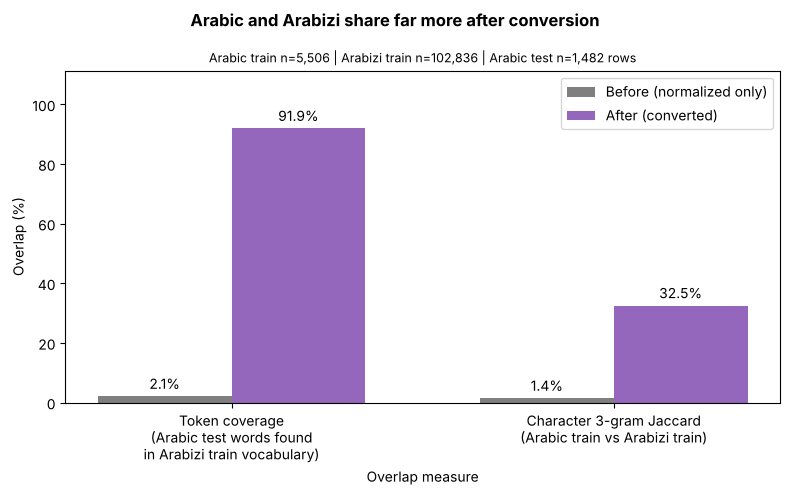

In [10]:
# 10. One before/after bar chart (200 dpi PNG)
BEFORE_COLOR, AFTER_COLOR = "#7f7f7f", "#9467bd"   # neutral colors: blue/orange are reserved for the two scripts
labels = ["Token coverage\n(Arabic test words found\nin Arabizi train vocabulary)",
          "Character 3-gram Jaccard\n(Arabic train vs Arabizi train)"]
before = [overlap_res.loc["before (text_norm)", "token_coverage"] * 100,
          overlap_res.loc["before (text_norm)", "char3_jaccard"] * 100]
after  = [overlap_res.loc["after (text_conv)", "token_coverage"] * 100,
          overlap_res.loc["after (text_conv)", "char3_jaccard"] * 100]

x = np.arange(2); w = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, before, w, label="Before (normalized only)", color=BEFORE_COLOR)
b2 = ax.bar(x + w/2, after,  w, label="After (converted)",        color=AFTER_COLOR)
ax.bar_label(b1, fmt="%.1f%%", padding=3); ax.bar_label(b2, fmt="%.1f%%", padding=3)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Overlap (%)"); ax.set_xlabel("Overlap measure")
ax.set_ylim(0, max(before + after) * 1.2 + 1)
fig.suptitle("Arabic and Arabizi share far more after conversion", fontweight="bold")
ax.set_title(f"Arabic train n={len(ar_train):,} | Arabizi train n={len(az_train):,} | Arabic test n={len(ar_test):,} rows", fontsize=9)
ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "04_conversion_overlap.png", dpi=200)
plt.show()

### Character error rate on the manual sample
For each row: reference = `convert(manual_text)`, output = `convert(original_text)`, CER = Levenshtein distance / reference length.
Two rows are excluded because the annotator censored offensive words, so they are not a faithful transcription.

In [11]:
# 11. Load the manual files
MANUAL_DIR = ROOT / "data" / "manual"
FILES = ["manual_aziz.csv", "manual_mouhib.csv"]          # manual_aziz.csv holds two 20-row sheets
COL_ORIG, COL_MANUAL = "original_text", "manual_text"
EXCLUDE_IDS = ["tsac_train_09424", "tsac_train_08880"]      # offensive words censored by the annotator

parts = []
for f in FILES:
    p = MANUAL_DIR / f
    if p.exists():
        d = pd.read_csv(p, encoding="utf-8", keep_default_na=False); d["annotator"] = f[7:-4]; parts.append(d)
    else:
        print("missing:", f)
man = pd.concat(parts, ignore_index=True)
missing = {COL_ORIG, COL_MANUAL} - set(man.columns)
assert not missing, f"columns {missing} not found. Available: {man.columns.tolist()}"

if "id" in man.columns:
    man = man[~man["id"].isin(EXCLUDE_IDS)]
n_all = len(man)
man = man[man[COL_MANUAL].str.strip() != ""].copy()
print(f"{len(man)} rows with a manual conversion ({n_all - len(man)} empty, skipped)")

# Direction: use the file's column if it has one, else detect the script of the original text
def script_of(t):
    ar = sum("\u0621" <= c <= "\u064A" or c in "ڤپچگ" for c in t)
    la = sum(c.isascii() and c.isalpha() or c in "éèêàâçùûôîï" for c in t)
    return "arabic" if ar >= la else "arabizi"
if "direction" not in man.columns:
    man["direction"] = man[COL_ORIG].map(script_of).map({"arabic": "Arabic → Arabizi", "arabizi": "Arabizi → Arabic"})
print(man["direction"].value_counts().to_string())

58 rows with a manual conversion (0 empty, skipped)
direction
ar_to_arabizi    43
arabizi_to_ar    15


In [12]:
from cleaning_utils import fix_text   # same encoding fix as the cleaning (e.g. the joined letter ﻹ)
# 12. CER and exact-word match, for both variants (keep_wy False = default, True = variant check)
def row_metrics(orig, manual, keep_wy):
    ref, out = convert(manual, keep_wy=keep_wy), convert(fix_text(orig), keep_wy=keep_wy)
    if not ref:
        return pd.Series({"ref": ref, "out": out, "cer": np.nan, "word_match": np.nan})
    ref_w, out_w = ref.split(), out.split()
    matched = sum((Counter(ref_w) & Counter(out_w)).values())
    return pd.Series({"ref": ref, "out": out,
                      "cer": Levenshtein.distance(ref, out) / len(ref),
                      "word_match": matched / len(ref_w)})

res = {}
for variant in (False, True):
    m = man.join(man.apply(lambda r: row_metrics(r[COL_ORIG], r[COL_MANUAL], variant), axis=1))
    res[variant] = m

def summary(m):
    by_dir = m.groupby("direction")[["cer", "word_match"]].mean()
    overall = m[["cer", "word_match"]].mean().rename("overall").to_frame().T
    return pd.concat([by_dir, overall]).round(4)

for variant, m in res.items():
    print(f"\n=== {'KEEP w,y (variant)' if variant else 'REMOVE w,y (default)'} | rows={m['cer'].notna().sum()} ===")
    print(summary(m).to_string())

cer_default, cer_variant = res[False]["cer"].mean(), res[True]["cer"].mean()
best_variant = cer_variant < cer_default
print(f"\nMean CER  default={cer_default:.4f}  variant(keep w,y)={cer_variant:.4f}  ->  keep: {'variant (set KEEP_WY=True in cell 4)' if best_variant else 'default'}")
print(f"Target 0.15 or less: {'PASS' if min(cer_default, cer_variant) <= 0.15 else 'NOT MET'}")


=== REMOVE w,y (default) | rows=58 ===
                  cer  word_match
ar_to_arabizi  0.1065      0.6201
arabizi_to_ar  0.1006      0.6813
overall        0.1050      0.6359

=== KEEP w,y (variant) | rows=58 ===
                  cer  word_match
ar_to_arabizi  0.1920      0.4005
arabizi_to_ar  0.2063      0.3780
overall        0.1957      0.3947

Mean CER  default=0.1050  variant(keep w,y)=0.1957  ->  keep: default
Target 0.15 or less: PASS


In [13]:
# 13. Worst 5 rows of the kept variant, with the error type found by reading each row
best = res[best_variant].copy()
worst = best.nlargest(5, "cer")[["annotator", "direction", COL_ORIG, COL_MANUAL, "ref", "out", "cer"]].copy()
ERROR_TYPES = {
    "tsac_train_07764": "word boundary (attached article ال)",
    "tunizi_091615":    "spelling habit (h, k, th for ح, ق, ض)",
    "tsac_train_07937": "word boundary (attached article ال)",
    "tsac_train_00258": "word boundary (attached article ال)",
    "tsac_train_12922": "annotator slip (emoji left out)",
}
worst_ids = best.loc[worst.index, "id"]
def word_diff(r):
    ref_w, out_w = Counter(r["ref"].split()), Counter(r["out"].split())
    return f"missing: {list((ref_w - out_w).elements())} | extra: {list((out_w - ref_w).elements())}"
worst["word_diff"] = worst.apply(word_diff, axis=1)
worst["error_type"] = worst_ids.map(ERROR_TYPES).fillna("not labelled")
pd.set_option("display.max_colwidth", 80)
print(worst.round(3).to_string(index=False))

annotator     direction                                                     original_text                                                               manual_text                                       ref                                             out   cer                                                                                                            word_diff                            error_type
     aziz ar_to_arabizi                                  هذه حقيقة الإخونج ... الخماج ...                                     hedhi el 79i9a el 7ounj … el khamaj …                  hdh l 79 l 7nj … l 5mj …                            hdh 79 l5nj . l5mj . 0.292                                 missing: ['l', 'l', 'l', '7nj', '…', '…', '5mj'] | extra: ['l5nj', '.', '.', 'l5mj']   word boundary (attached article ال)
   mouhib arabizi_to_ar                          bessaraha jaballi mandouch mawkef watheh                                          بصراحة جابالي ما عندوش موقف واضح       

In [14]:
# 14. Save results
best.to_csv(PROC_DIR / "cer_rows.csv", index=False, encoding="utf-8")
worst.to_csv(PROC_DIR / "cer_worst5.csv", index=False, encoding="utf-8")
print("Saved cer_rows.csv, cer_worst5.csv, overlap_results.csv, and figures/04_conversion_overlap.png")

Saved cer_rows.csv, cer_worst5.csv, overlap_results.csv, and figures/04_conversion_overlap.png
